# HEP et réponse de la peau (SCR)

**Idée** : la note d'arousal est subjective et le HEP ne la suit pas ([`laura_hep_groupe.ipynb`](laura_hep_groupe.ipynb)).
La peau, elle, réagit davantage aux vidéos notées comme activantes (Hugo, branche `hugo/brain-skin`, 3.2c).
**Question** : le cerveau « écoute »-t-il le cœur différemment pendant les vidéos où **le corps réagit
vraiment** (une réponse de la peau, SCR) que pendant celles où il ne réagit pas ?

**Méthode** :
- détection des SCR avec les fonctions de Hugo, reprises sans changement dans [`gsr_utils.py`](gsr_utils.py) ;
- une vidéo est « avec SCR » si une SCR (hors artefact) démarre entre +1 et +11 s après son début
  (définition « scr_any » de Hugo) ; toutes les vidéos sont utilisées, notées ou non ;
- HEP fronto-central des battements des vidéos avec SCR vs sans SCR, pour chaque participant
  (battements déjà calculés par [`hep_group.py`](hep_group.py)) ;
- fenêtres définies sur la moyenne des deux conditions, rien avant 100 ms
  (même règle que [`laura_hep_corrections.ipynb`](laura_hep_corrections.ipynb)).

**Différences avec Hugo** : données CURATED (Hugo : PREPROCESSED), jours 1 et 2 (Hugo : jour 1),
participants de l'analyse HEP (4 en commun avec Hugo).

In [1]:
import os
os.environ.setdefault("HABS_DATA", r"C:\Users\ehren\habs-data")   # à adapter sur ta machine

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from gsr_utils import FG, FLAT_RANGE, gsr_qc, read_gsr, scr_detect, scr_per_video, smooth_gsr
from hep_utils import frac_area_latency, mean_amp, video_trials, load_labels
from hep_group import available_days

ROOT = Path(os.environ["HABS_DATA"]) / "derivatives" / "hep"
plt.rcParams["figure.dpi"] = 90
MIN_BEATS = 50
rv = pd.read_csv(ROOT / "resume.csv")
subjects = sorted(rv[(rv.battements_basse >= MIN_BEATS) & (rv.battements_haute >= MIN_BEATS)].subj)
labels = load_labels()
print(f"{len(subjects)} participants de l'analyse HEP")

22 participants de l'analyse HEP


## 1. Peau : contrôle qualité et détection des SCR
Capteur « plat » (étendue < 0,05 µS, critère de Hugo) → jour exclu.

In [2]:
qc_rows, vid_rows = [], []
for s in subjects:
    for d in available_days(s):
        g = smooth_gsr(read_gsr(s, day=d))
        q = gsr_qc(g); flat = q["range_uS"] < FLAT_RANGE
        tr = video_trials(s, d, labels=labels)
        scr = scr_detect(g)
        qc_rows.append({"subj": s, "day": d, **q, "plat": flat, "scr_par_min": len(scr) / (len(g) / FG) * 60,
                        "artefacts_pct": 100 * scr.artefact.mean() if len(scr) else np.nan})
        if flat:
            continue
        ok = tr.on_s + 11 <= len(g) / FG
        for (has, amp), r in zip(scr_per_video(scr, tr.on_s[ok]), tr[ok].itertuples()):
            vid_rows.append({"subj": s, "day": d, "trial": r.trial, "arousal": r.arousal, "scr": has, "amp_uS": amp})
qc = pd.DataFrame(qc_rows); vids = pd.DataFrame(vid_rows)
print("Jours exclus (capteur plat) :", qc[qc.plat][["subj", "day"]].values.tolist() or "aucun")
per = vids.groupby("subj").scr.agg(["size", "mean"]).rename(columns={"size": "vidéos", "mean": "part avec SCR"})
print(f"Vidéos avec SCR : médiane {per['part avec SCR'].median():.0%} par participant "
      f"(de {per['part avec SCR'].min():.0%} à {per['part avec SCR'].max():.0%})")
per.T.round(2)

Jours exclus (capteur plat) : [['P006', 2], ['P017', 1], ['P026', 1], ['P026', 2], ['P106', 1], ['P106', 2], ['P124', 1], ['P178', 1], ['P178', 2], ['P181', 2], ['P193', 2], ['P298', 1], ['P298', 3], ['P302', 3], ['P316', 1]]
Vidéos avec SCR : médiane 17% par participant (de 4% à 50%)


subj,P001,P017,P020,P027,P090,P124,P138,P165,P177,P181,P187,P193,P210,P212,P302,P354
vidéos,106.00,71.00,107.00,70.0,107.00,70.00,107.00,106.00,54.0,53.00,106.00,54.0,106.00,108.00,70.00,108.00
part avec SCR,0.25,0.04,0.11,0.1,0.37,0.14,0.05,0.25,0.5,0.06,0.39,0.2,0.05,0.06,0.33,0.25


## 2. Vérification : retrouve-t-on le résultat de Hugo ?
Chez Hugo, les SCR sont un peu plus fréquentes après les vidéos notées comme activantes. Si on retrouve
ce lien chez nos participants, la détection est cohérente avec la sienne malgré les différences de données.

In [3]:
rho = vids.dropna(subset=["arousal"]).groupby("subj").apply(
    lambda d: stats.spearmanr(d.arousal, d.scr).statistic if d.scr.nunique() > 1 else np.nan, include_groups=False).dropna()
w = stats.wilcoxon(rho)
print(f"Corrélation note d'arousal ↔ présence d'une SCR : médiane rho = {rho.median():.3f}, "
      f"{(rho > 0).sum()}/{len(rho)} participants positifs, Wilcoxon p = {w.pvalue:.4f}")
print("(Hugo, 18 participants, jour 1, PREPROCESSED : médiane rho = 0,161, p = 0,003)")

Corrélation note d'arousal ↔ présence d'une SCR : médiane rho = 0.109, 11/16 participants positifs, Wilcoxon p = 0.0110
(Hugo, 18 participants, jour 1, PREPROCESSED : médiane rho = 0,161, p = 0,003)


## 3. HEP : vidéos avec SCR vs sans SCR

In [4]:
times = None; A, B, rr_a, rr_b, kept, nb = [], [], [], [], [], []
scr_of = {(r.subj, f"{r.day}_{r.trial}"): r.scr for r in vids.itertuples()}
for s in subjects:
    D = np.load(ROOT / f"{s}.npz"); times = D["times"]
    flag = np.array([scr_of.get((s, v), np.nan) for v in D["wave_video"]], dtype=float)
    yes, no = flag == 1, flag == 0
    if yes.sum() < MIN_BEATS or no.sum() < MIN_BEATS:
        continue
    kept.append(s); nb.append((yes.sum(), no.sum()))
    A.append(D["waves"][no].mean(0)); B.append(D["waves"][yes].mean(0))
    rr_a.append(np.nanmean(D["wave_rr"][no])); rr_b.append(np.nanmean(D["wave_rr"][yes]))
A, B = np.array(A), np.array(B); rr_a, rr_b = np.array(rr_a) * 1000, np.array(rr_b) * 1000
nb = np.array(nb)
print(f"{len(kept)} participants avec ≥ {MIN_BEATS} battements dans chaque condition "
      f"(médiane : {np.median(nb[:, 0]):.0f} battements avec SCR, {np.median(nb[:, 1]):.0f} sans)")
print("Exclus faute de battements :", sorted(set(subjects) - set(kept)) or "aucun")

13 participants avec ≥ 50 battements dans chaque condition (médiane : 159 battements avec SCR, 610 sans)
Exclus faute de battements : ['P006', 'P017', 'P026', 'P106', 'P138', 'P178', 'P181', 'P298', 'P316']


Latence (composante négative) : sans SCR 222 ms, avec SCR 238 ms ; différence +16 ± 18 ms (jackknife), p = 0.402


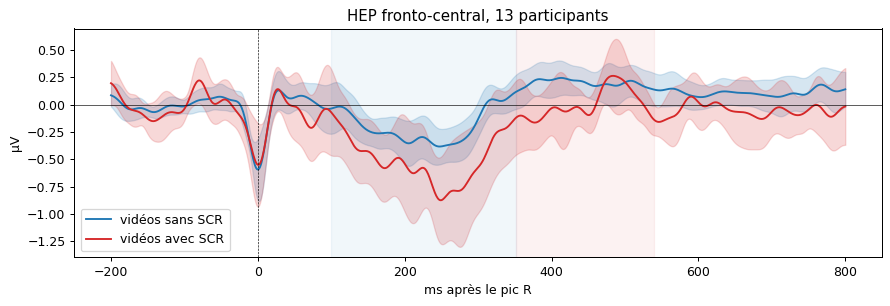

,composante,fenêtre (ms),sans SCR (µV),avec SCR (µV),avec − sans,p (t),p (Wilcoxon),participants avec > sans
0,négative,100–351,-0.195,-0.503,-0.308,0.033,0.027,3/13
1,positive,352–539,0.197,0.005,-0.192,0.096,0.094,5/13


In [5]:
QRS_END = 0.10
def comp_window(w, sign, after=QRS_END, tmax=0.6):
    m = (times >= after) & (times <= tmax)
    i = np.where(m)[0][np.argmax(sign * w[m])]
    a = i
    while a > 0 and sign * w[a - 1] > 0 and times[a - 1] >= QRS_END: a -= 1
    b = i
    while b < len(w) - 1 and sign * w[b + 1] > 0 and times[b + 1] <= tmax: b += 1
    return times[a], times[b]

pooled = (A.mean(0) + B.mean(0)) / 2
neg = comp_window(pooled, -1); pos = comp_window(pooled, +1, after=neg[1])
rows = []
for name, win in [("négative", neg), ("positive", pos)]:
    d = mean_amp(B, times, win) - mean_amp(A, times, win)
    rows.append({"composante": name, "fenêtre (ms)": f"{win[0]*1000:.0f}–{win[1]*1000:.0f}",
                 "sans SCR (µV)": mean_amp(A, times, win).mean(), "avec SCR (µV)": mean_amp(B, times, win).mean(),
                 "avec − sans": d.mean(), "p (t)": stats.ttest_1samp(d, 0).pvalue, "p (Wilcoxon)": stats.wilcoxon(d).pvalue,
                 "participants avec > sans": f"{(d > 0).sum()}/{len(d)}"})
lat = lambda w: frac_area_latency(w, times, win=neg, polarity=-1)
n = len(A); full = lat(B.mean(0)) - lat(A.mean(0))
loo = np.array([lat(np.delete(B, i, 0).mean(0)) - lat(np.delete(A, i, 0).mean(0)) for i in range(n)])
se = np.sqrt((n - 1) / n * ((loo - loo.mean()) ** 2).sum()); t = full / se
print(f"Latence (composante négative) : sans SCR {lat(A.mean(0))*1000:.0f} ms, avec SCR {lat(B.mean(0))*1000:.0f} ms ; "
      f"différence {full*1000:+.0f} ± {se*1000:.0f} ms (jackknife), p = {2*stats.t.sf(abs(t), n-1):.3f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
for x, lab, col in [(A, "vidéos sans SCR", "C0"), (B, "vidéos avec SCR", "C3")]:
    m, e = x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x))
    ax.fill_between(times * 1000, m - 1.96 * e, m + 1.96 * e, color=col, alpha=.18); ax.plot(times * 1000, m, color=col, label=lab)
ax.axvspan(neg[0] * 1000, neg[1] * 1000, color="C0", alpha=.06); ax.axvspan(pos[0] * 1000, pos[1] * 1000, color="C3", alpha=.06)
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5, ls="--"); ax.legend()
ax.set_xlabel("ms après le pic R"); ax.set_ylabel("µV"); ax.set_title(f"HEP fronto-central, {len(kept)} participants")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

## 4. Contrôles
1. **Rythme cardiaque** : une SCR s'accompagne souvent d'un changement du rythme cardiaque ; s'il diffère,
   l'artefact cardiaque peut créer une fausse différence de HEP.
2. **Arousal** : les vidéos avec SCR sont-elles notées plus activantes ? (Si oui, ce contraste recoupe en
   partie celui de haute vs basse.)

In [6]:
d_rr = rr_b - rr_a
print(f"RR : sans SCR {rr_a.mean():.0f} ms, avec SCR {rr_b.mean():.0f} ms ; différence {d_rr.mean():+.1f} ms, "
      f"p = {stats.ttest_1samp(d_rr, 0).pvalue:.3f}")
ar = vids.dropna(subset=["arousal"]).groupby(["subj", "scr"]).arousal.mean().unstack().dropna()
print(f"Note d'arousal moyenne : sans SCR {ar[False].mean():.2f}, avec SCR {ar[True].mean():.2f} ; "
      f"Wilcoxon p = {stats.wilcoxon(ar[True] - ar[False]).pvalue:.4f}")

RR : sans SCR 838 ms, avec SCR 820 ms ; différence -18.0 ms, p = 0.007
Note d'arousal moyenne : sans SCR 5.07, avec SCR 5.64 ; Wilcoxon p = 0.0155


## 5. Contrôle décisif : battements appariés en rythme cardiaque

Le cœur bat plus vite dans les vidéos avec SCR. Pour l'écarter comme explication, on compare des
battements **de même intervalle RR** : pour chaque participant et chaque tranche de RR de 20 ms, on tire
au hasard autant de battements dans les deux conditions. Les deux groupes ont alors le même rythme
cardiaque. Mêmes fenêtres que la section 3.

In [7]:
rng = np.random.default_rng(0)
bins = np.arange(0.3, 2.0, 0.02)
res = []
for s in kept:
    D = np.load(ROOT / f"{s}.npz"); w, rr = D["waves"], D["wave_rr"]
    f = np.array([scr_of.get((s, v), np.nan) for v in D["wave_video"]], float)
    ok = ~np.isnan(rr) & ~np.isnan(f)
    yes, no = np.where(ok & (f == 1))[0], np.where(ok & (f == 0))[0]
    by, bn = np.digitize(rr[yes], bins), np.digitize(rr[no], bins)
    sy, sn = [], []
    for b in np.unique(by):
        iy, i_n = yes[by == b], no[bn == b]; k = min(len(iy), len(i_n))
        if k:
            sy += list(rng.choice(iy, k, replace=False)); sn += list(rng.choice(i_n, k, replace=False))
    if len(sy) < 40:
        continue
    res.append({"subj": s, "battements appariés": len(sy), "RR avec − sans (ms)": 1000 * (rr[sy].mean() - rr[sn].mean()),
                "négative avec − sans (µV)": mean_amp(w[sy].mean(0), times, neg) - mean_amp(w[sn].mean(0), times, neg),
                "positive avec − sans (µV)": mean_amp(w[sy].mean(0), times, pos) - mean_amp(w[sn].mean(0), times, pos)})
res = pd.DataFrame(res)
print(f"{len(res)} participants, médiane {res['battements appariés'].median():.0f} battements par condition ; "
      f"différence de RR restante : {res['RR avec − sans (ms)'].mean():+.1f} ms")
for c in ["négative avec − sans (µV)", "positive avec − sans (µV)"]:
    print(f"  {c} : {res[c].mean():+.3f}, p (t) = {stats.ttest_1samp(res[c], 0).pvalue:.3f}, "
          f"p (Wilcoxon) = {stats.wilcoxon(res[c]).pvalue:.3f}, {(res[c] < 0).sum()}/{len(res)} négatifs")
d_neg = mean_amp(B, times, neg) - mean_amp(A, times, neg)
r, p_r = stats.pearsonr(d_rr, d_neg)
print(f"Sans appariement : lien différence de RR ↔ différence de HEP entre participants : r = {r:.2f}, p = {p_r:.3f}")
res.round(3)

13 participants, médiane 148 battements par condition ; différence de RR restante : -0.3 ms
  négative avec − sans (µV) : -0.344, p (t) = 0.183, p (Wilcoxon) = 0.244, 8/13 négatifs
  positive avec − sans (µV) : -0.208, p (t) = 0.291, p (Wilcoxon) = 0.244, 9/13 négatifs
Sans appariement : lien différence de RR ↔ différence de HEP entre participants : r = -0.04, p = 0.901


,subj,battements appariés,RR avec − sans (ms),négative avec − sans (µV),positive avec − sans (µV)
0,P001,266,0.011,-0.506,-0.482
1,P020,89,0.068,-0.778,-0.783
2,P027,82,-0.256,-0.363,-0.321
3,P090,300,0.220,0.376,-0.036
4,P124,91,-1.253,0.411,1.011
5,P165,220,-0.559,-0.078,-0.182
6,P177,163,0.644,-0.162,-0.357
7,P187,237,0.279,0.219,0.115
8,P193,78,-1.321,-0.767,-0.195
9,P210,51,-1.980,0.457,0.195


## 6. Bilan

**13 participants** analysables (beaucoup de capteurs de peau défectueux dans cet échantillon : 15 journées
exclues, capteur saturé ou débranché ; d'autres participants n'ont pas assez de vidéos avec SCR).

1. **La détection est cohérente avec celle de Hugo** : chez nos participants aussi, les vidéos notées plus
   activantes sont un peu plus souvent suivies d'une SCR (rho médian 0,11, p = 0,011 ; Hugo : 0,16).
2. **Le HEP semble plus négatif pendant les vidéos avec SCR** (partie 100–351 ms : −0,31 µV, p = 0,03,
   10 participants sur 13).
3. **Mais ce n'est pas confirmé** : le cœur bat plus vite dans ces vidéos (RR −18 ms, p = 0,007). À rythme
   cardiaque égal (battements appariés), l'effet garde une taille comparable (−0,34 µV) mais n'est plus
   significatif (p = 0,18), avec beaucoup moins de battements. L'explication cardiaque n'est pas
   probable (aucun lien entre différence de RR et différence de HEP d'un participant à l'autre, r = −0,04),
   mais elle n'est pas exclue. Le p = 0,03 n'est pas corrigé pour les deux fenêtres testées (seuil
   corrigé : 0,025).

**Comment le lire** : c'est une **piste**, pas un résultat. Contrairement à la note d'arousal, la réaction
réelle du corps (la peau) pourrait aller avec un HEP différent. C'est cohérent avec l'idée que le HEP suit
l'état du corps plutôt que le ressenti déclaré, mais il faudrait plus de participants avec un bon capteur
de peau pour trancher.

**Limites** : 13 participants ; groupe fronto-central seulement (pas de test sur tout le scalp sans relancer
le traitement) ; une SCR peut démarrer jusqu'à 11 s après le début de la vidéo, donc une partie des
battements « avec SCR » précède la réponse de la peau ; vidéos avec SCR un peu plus activantes
(note 5,6 vs 5,1), donc les deux contrastes se recoupent en partie.